# 01 — Data EDA

Exploratory analysis of METR-LA (DCRNN protocol). All cells run top-to-bottom.  
Figures saved to `results/figures/eda/`.

In [1]:
import sys, os
from pathlib import Path

# Always run from project root so all relative paths resolve correctly
ROOT = Path("..").resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from src.data.adjacency import load_adjacency, compute_normalized_laplacian, laplacian_eigendecomposition
from src.utils.config import load_config

FIG_DIR = Path("results/figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print(f"Working directory: {Path.cwd()}")


Working directory: /Users/serkan/Projects/research-tud


## Load data

In [2]:
df_raw = pd.read_hdf("data/raw/metr-la.h5")
T, N = df_raw.shape
print(f"METR-LA: T={T}, N={N}")
print(f"Date range: {df_raw.index[0]}  →  {df_raw.index[-1]}")

train_npz  = np.load("data/processed/metrla_train.npz")
scaler     = load_config("data/processed/metrla_scaler.yaml")
MEAN, STD  = scaler["mean"], scaler["std"]
print(f"Scaler  mean={MEAN:.4f}  std={STD:.4f}")

x_train    = train_npz["x"]
y_train    = train_npz["y"]
mask_train = train_npz["x_mask"]
print(f"x_train: {x_train.shape}  y_train: {y_train.shape}")

adj = load_adjacency("metrla")
L   = compute_normalized_laplacian(adj)
eigenvalues, eigenvectors = laplacian_eigendecomposition(L, "metrla")
print(f"Laplacian eigenvalue range: [{eigenvalues.min():.4f}, {eigenvalues.max():.4f}]")


METR-LA: T=34272, N=207
Date range: 2012-03-01 00:00:00  →  2012-06-27 23:55:00
Scaler  mean=54.4059  std=19.4943


x_train: (23967, 12, 207, 2)  y_train: (23967, 12, 207, 1)
Laplacian eigenvalue range: [0.0000, 1.7062]


/Users/serkan/Projects/research-tud/src/data/adjacency.py:40: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  _, _, adj_mx = pickle.load(f, encoding="latin1")
/Users/serkan/Projects/research-tud/src/data/adjacency.py:65: RuntimeWarning: divide by zero encountered in divide
  d_inv_sqrt = np.where(d > 0, 1.0 / np.sqrt(d), 0.0)


## Verification: y not normalised, time-of-day channel

In [3]:
# Deliverable 5: y must be raw mph (NOT normalised). Mean ~54 mph for METR-LA.
y_mean = float(y_train.mean())
y_std  = float(y_train.std())
print(f"y_train mean  = {y_mean:.4f} mph   (expect ~54, NOT ~0)")
print(f"y_train std   = {y_std:.4f} mph   (expect ~19, NOT ~1)")
assert y_mean > 10.0, f"y looks normalised: mean={y_mean:.4f}"

# Deliverable 6: x[...,1] must be continuous float in [0,1), NOT integer index.
tod_sample = x_train[:5, 0, 0, 1]
print(f"\nx_train[:5, 0, 0, 1] (time-of-day, first 5 windows):")
print(f"  {tod_sample}  ← floats in [0,1), not integers")

y_train mean  = 54.4056 mph   (expect ~54, NOT ~0)
y_train std   = 19.4938 mph   (expect ~19, NOT ~1)

x_train[:5, 0, 0, 1] (time-of-day, first 5 windows):
  [0.         0.00347222 0.00694444 0.01041667 0.01388889]  ← floats in [0,1), not integers


## Figure 1 — Weekly cycles

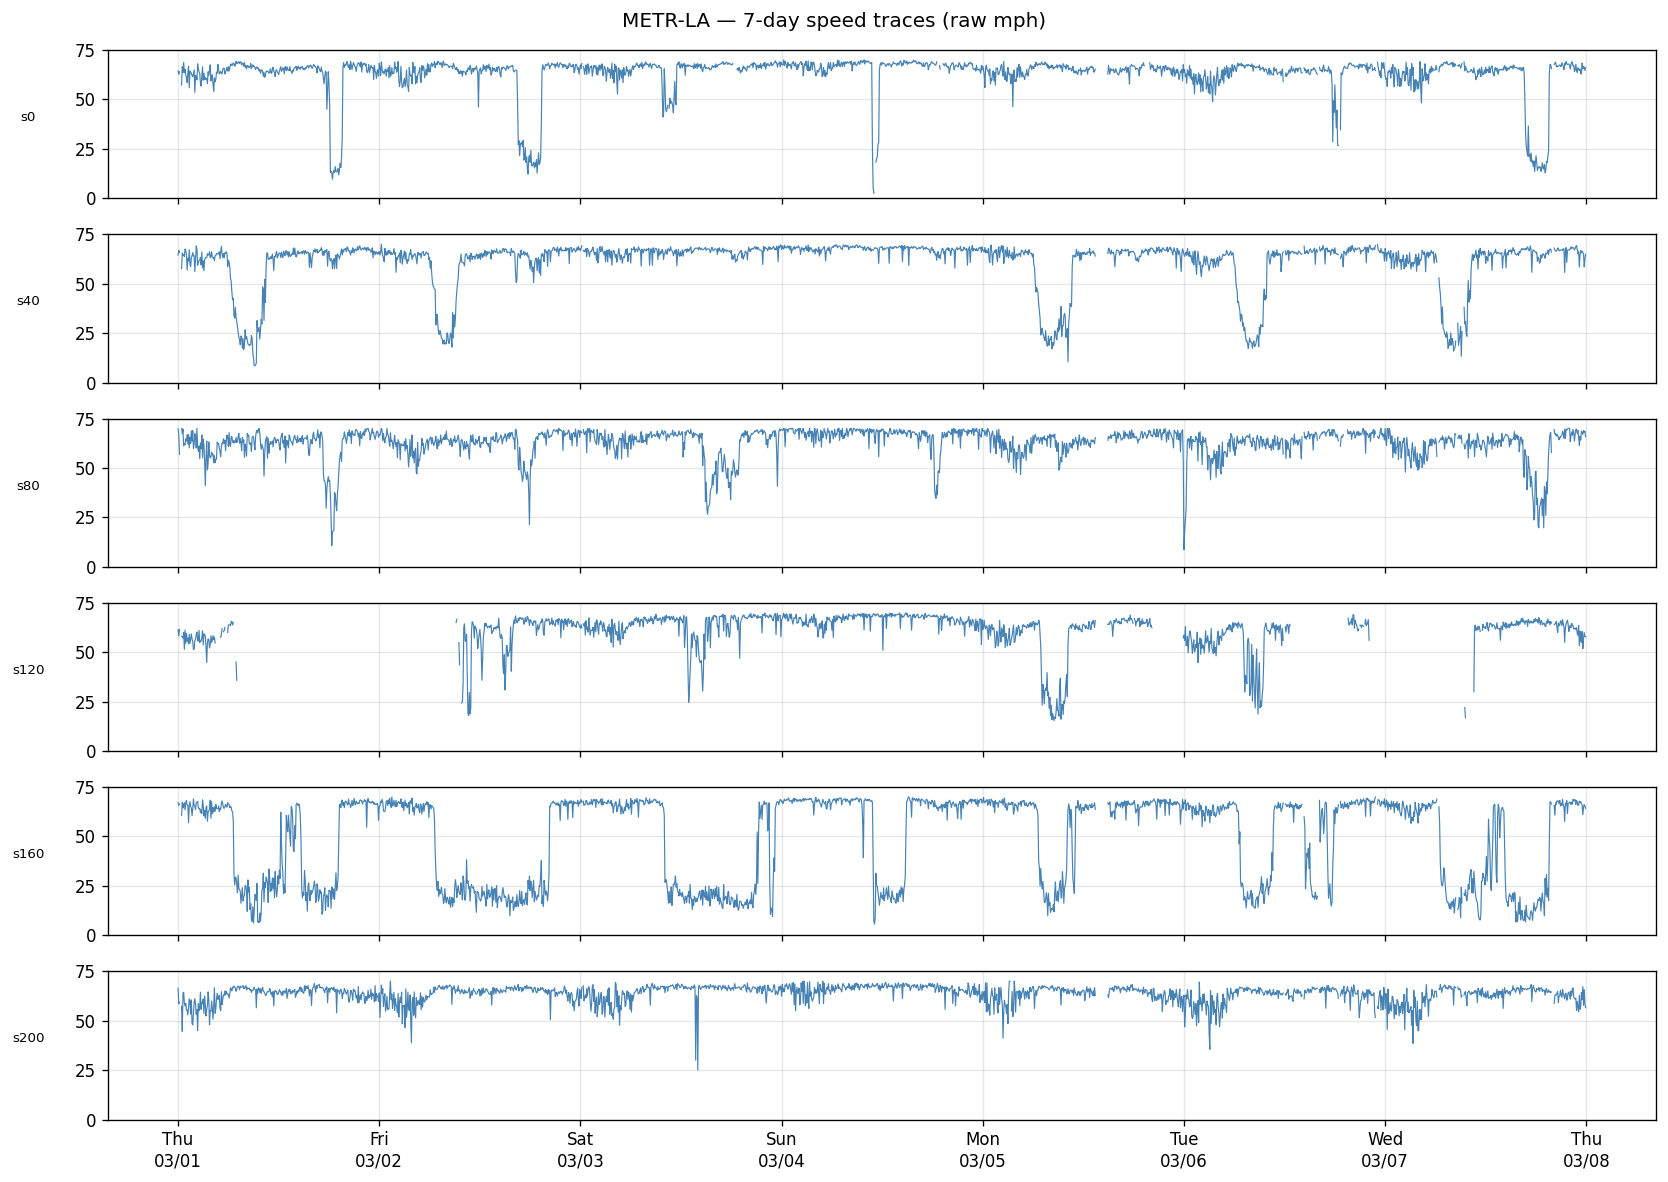

Saved fig_weekly_cycles.png


In [4]:
SENSORS  = [0, 40, 80, 120, 160, 200]
N_DAYS   = 7
N_STEPS  = N_DAYS * 288          # 288 five-min slots per day

fig, axes = plt.subplots(len(SENSORS), 1, figsize=(14, 10), sharex=True)
fig.suptitle('METR-LA — 7-day speed traces (raw mph)', fontsize=12)

times = df_raw.index[:N_STEPS]
for ax, s in zip(axes, SENSORS):
    speed = df_raw.values[:N_STEPS, s].copy().astype(float)
    speed[speed == 0.0] = np.nan          # show missing as gaps
    ax.plot(times, speed, linewidth=0.7, color='steelblue')
    ax.set_ylabel(f's{s}', fontsize=8, rotation=0, labelpad=28)
    ax.set_ylim(0, 75)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(25))
    ax.grid(alpha=0.3)

axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%a\n%m/%d'))
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_weekly_cycles.png', bbox_inches='tight')
plt.show()
print('Saved fig_weekly_cycles.png')

## Figure 2 — Missingness heatmap

Sensors with >10% missing: 34
Max missing rate: 20.1%  (sensor 105)


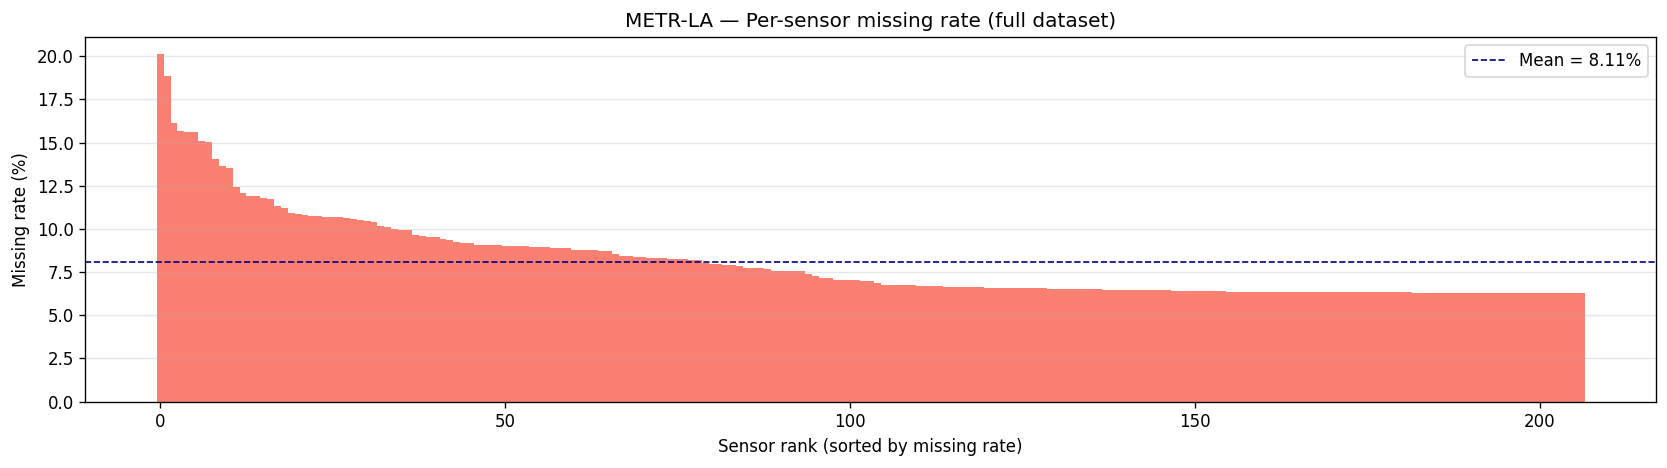

Saved fig_missingness_heatmap.png


In [5]:
# Per-sensor missing rate across the FULL dataset (not just train)
missing_rate = (df_raw.values == 0.0).mean(axis=0)   # (207,)
order = np.argsort(missing_rate)[::-1]               # descending

print(f'Sensors with >10% missing: {(missing_rate > 0.1).sum()}')
print(f'Max missing rate: {missing_rate.max()*100:.1f}%  (sensor {missing_rate.argmax()})')

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(np.arange(N), missing_rate[order] * 100, width=1.0, color='salmon', edgecolor='none')
ax.set_xlabel('Sensor rank (sorted by missing rate)')
ax.set_ylabel('Missing rate (%)')
ax.set_title('METR-LA — Per-sensor missing rate (full dataset)')
ax.axhline(missing_rate.mean()*100, color='navy', linestyle='--', linewidth=1,
           label=f'Mean = {missing_rate.mean()*100:.2f}%')
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_missingness_heatmap.png', bbox_inches='tight')
plt.show()
print('Saved fig_missingness_heatmap.png')

## Figure 3 — ACF: raw vs de-meaned speed

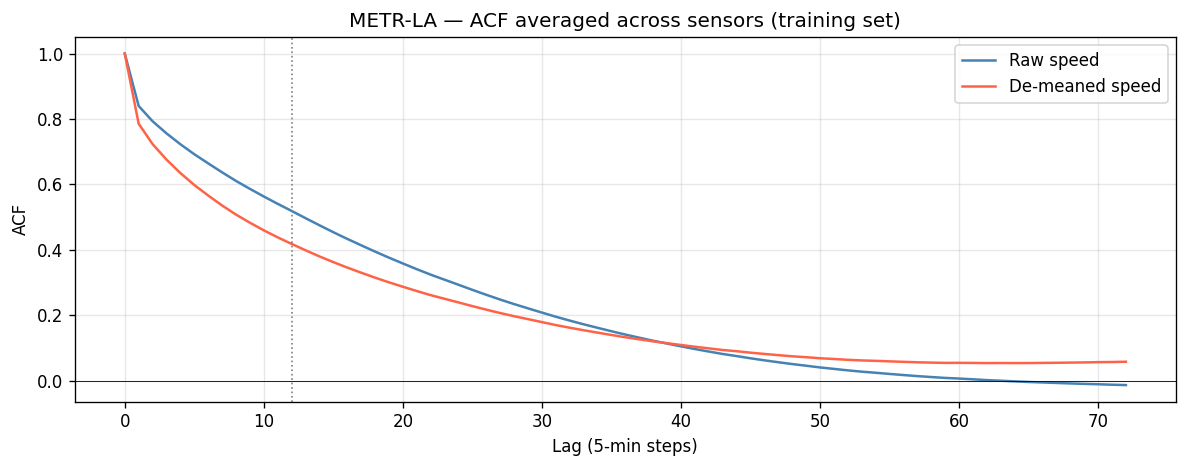

Saved fig_acf_raw_vs_demeaned.png


In [6]:
from statsmodels.tsa.stattools import acf

MAX_LAG    = 72    # 6 hours at 5-min resolution
N_TRAIN_T  = 23990

# Use raw speed from the training portion only
speed_train = df_raw.values[:N_TRAIN_T].astype(float)   # (23990, 207)

# Per-sensor, per-time-of-day mean on training set
tod_idx = (df_raw.index[:N_TRAIN_T].values
           - df_raw.index[:N_TRAIN_T].values.astype('datetime64[D]')
          ) / np.timedelta64(5, 'm')                     # 0-287
tod_idx = tod_idx.astype(int)

tod_means = np.zeros((288, N))   # (288 slots, 207 sensors)
for slot in range(288):
    mask = tod_idx == slot
    if mask.sum() > 0:
        vals = speed_train[mask]
        valid_vals = np.where(vals == 0, np.nan, vals)
        tod_means[slot] = np.nanmean(valid_vals, axis=0)

speed_demeaned = speed_train.copy()
for t in range(N_TRAIN_T):
    speed_demeaned[t] -= tod_means[tod_idx[t]]

# Compute ACF averaged across sensors (skip sensors with >50% missing)
good_sensors = np.where(missing_rate < 0.5)[0]
acf_raw  = np.zeros((len(good_sensors), MAX_LAG + 1))
acf_dem  = np.zeros((len(good_sensors), MAX_LAG + 1))

for i, s in enumerate(good_sensors):
    raw_s = speed_train[:, s].copy()
    raw_s[raw_s == 0] = np.nan
    valid = ~np.isnan(raw_s)
    if valid.sum() > MAX_LAG * 2:
        acf_raw[i] = acf(raw_s[valid], nlags=MAX_LAG, fft=True)
        dem_s = speed_demeaned[:, s]
        dem_s = dem_s[valid]
        acf_dem[i] = acf(dem_s, nlags=MAX_LAG, fft=True)

mean_acf_raw = acf_raw.mean(axis=0)
mean_acf_dem = acf_dem.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
lags = np.arange(MAX_LAG + 1)
ax.plot(lags, mean_acf_raw, label='Raw speed',      color='steelblue', linewidth=1.5)
ax.plot(lags, mean_acf_dem, label='De-meaned speed', color='tomato',    linewidth=1.5)
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Lag (5-min steps)')
ax.set_ylabel('ACF')
ax.set_title('METR-LA — ACF averaged across sensors (training set)')
ax.legend()
ax.grid(alpha=0.3)
# Mark 12-step forecast horizon
ax.axvline(12, color='gray', linestyle=':', linewidth=1, label='h=12')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_acf_raw_vs_demeaned.png', bbox_inches='tight')
plt.show()
print('Saved fig_acf_raw_vs_demeaned.png')

## Figure 4 — Dirichlet energy distribution

Mean Dirichlet energy: 0.068068
Median:                0.060212


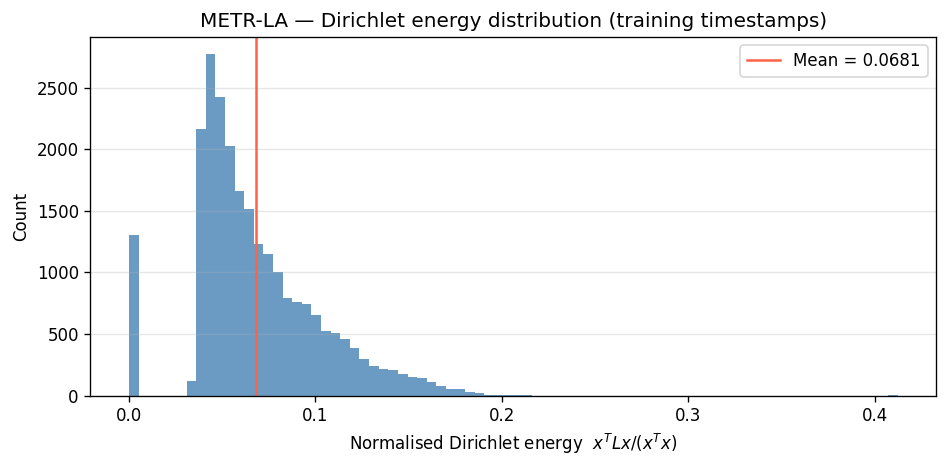

Saved fig_dirichlet_energy_distribution.png


In [7]:
# For each training timestamp, compute normalised Dirichlet energy:
#   E(t) = x_t^T L x_t / (x_t^T x_t + 1e-8)
# where x_t is the raw speed vector at time t (missing = 0)

L32 = L.astype(np.float32)
speed_t = df_raw.values[:N_TRAIN_T].astype(np.float32)   # (T_train, 207)

# Vectorised: x @ L @ x^T diagonal = (x @ L) * x summed over sensors
xL  = speed_t @ L32                          # (T_train, 207)
xLx = (xL * speed_t).sum(axis=1)            # (T_train,)
xx  = (speed_t * speed_t).sum(axis=1)       # (T_train,)
dirichlet = xLx / (xx + 1e-8)               # (T_train,)

mean_dirichlet = float(dirichlet.mean())
print(f'Mean Dirichlet energy: {mean_dirichlet:.6f}')
print(f'Median:                {np.median(dirichlet):.6f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dirichlet, bins=80, color='steelblue', edgecolor='none', alpha=0.8)
ax.axvline(mean_dirichlet, color='tomato', linewidth=1.5,
           label=f'Mean = {mean_dirichlet:.4f}')
ax.set_xlabel(r'Normalised Dirichlet energy  $x^T L x / (x^T x)$')
ax.set_ylabel('Count')
ax.set_title('METR-LA — Dirichlet energy distribution (training timestamps)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_dirichlet_energy_distribution.png', bbox_inches='tight')
plt.show()
print('Saved fig_dirichlet_energy_distribution.png')

## Regime labels for test windows

In [8]:
# Load test split (raw y = raw mph)
test_npz  = np.load("data/processed/metrla_test.npz")
x_test    = test_npz["x"]        # (6831, 12, 207, 2)  — channel 0 is RAW speed (not normalised)
x_mask    = test_npz["x_mask"]   # (6831, 12, 207, 1)

# x[...,0] is already raw mph — the .npz stores un-normalised values.
# Normalisation only happens inside TrafficDataset, not in the saved files.
raw_x_speed = x_test[..., 0]                        # (6831, 12, 207) raw mph

# Mean speed per window: masked average over time steps × sensors
valid = x_mask[..., 0].astype(bool)                 # (6831, 12, 207)
masked_speed = np.where(valid, raw_x_speed, np.nan)
window_mean_speed = np.nanmean(masked_speed.reshape(len(x_test), -1), axis=1)  # (6831,)

# ~531 all-missing windows produce NaN mean → assign them to transition
global_mean = float(np.nanmean(window_mean_speed))
window_mean_speed = np.where(np.isnan(window_mean_speed), global_mean, window_mean_speed)

# Tercile split
t33, t67 = np.percentile(window_mean_speed, [33.33, 66.67])
regime = np.where(window_mean_speed >= t67, "free_flow",
         np.where(window_mean_speed <= t33, "congested", "transition"))

print(f"Test windows: {len(regime)}")
for r in ["free_flow", "transition", "congested"]:
    n = (regime == r).sum()
    print(f"  {r:12s}: {n} ({n/len(regime)*100:.1f}%)")
print(f"Speed thresholds: congested<{t33:.1f} mph, free_flow>{t67:.1f} mph")

out_path = Path("data/processed/metrla_regimes_test.npz")
np.savez(out_path, regime=regime)
print(f"Saved regime labels → {out_path}")


Test windows: 6831
  free_flow   : 2277 (33.3%)
  transition  : 2277 (33.3%)
  congested   : 2277 (33.3%)
Speed thresholds: congested<57.2 mph, free_flow>61.0 mph
Saved regime labels → data/processed/metrla_regimes_test.npz


/var/folders/2h/kx4d21t52h3bwhwx2r_zzb500000gn/T/ipykernel_25110/3919316952.py:13: RuntimeWarning: Mean of empty slice
  window_mean_speed = np.nanmean(masked_speed.reshape(len(x_test), -1), axis=1)  # (6831,)


---
## PEMS-BAY analysis

Mirrors the METR-LA analysis for the second dataset: Laplacian eigendecomposition,
Dirichlet energy, and regime labels for the test split.

In [9]:
# Load PEMS-BAY raw data and processed splits
df_bay = pd.read_hdf("data/raw/pems-bay.h5")
T_bay, N_bay = df_bay.shape
print(f"PEMS-BAY: T={T_bay}, N={N_bay}")
print(f"Date range: {df_bay.index[0]}  →  {df_bay.index[-1]}")

train_bay  = np.load("data/processed/pemsbay_train.npz")
test_bay   = np.load("data/processed/pemsbay_test.npz")
scaler_bay = load_config("data/processed/pemsbay_scaler.yaml")
MEAN_BAY, STD_BAY = scaler_bay["mean"], scaler_bay["std"]
print(f"Scaler  mean={MEAN_BAY:.4f}  std={STD_BAY:.4f}")
print(f"x_train: {train_bay['x'].shape}  y_train: {train_bay['y'].shape}")

# Verify y not normalised
y_bay_mean = float(train_bay['y'].mean())
print(f"y_train mean = {y_bay_mean:.4f} mph  (expect raw mph ~63, NOT ~0)")
assert y_bay_mean > 10.0, f"y looks normalised: mean={y_bay_mean:.4f}"

# Missing rate
missing_rate_bay = (df_bay.values == 0.0).mean(axis=0)
print(f"Missing rate: {missing_rate_bay.mean()*100:.3f}% mean, {missing_rate_bay.max()*100:.1f}% max")

PEMS-BAY: T=52116, N=325
Date range: 2017-01-01 00:00:00  →  2017-06-30 23:55:00
Scaler  mean=62.7369  std=9.4368


x_train: (36458, 12, 325, 2)  y_train: (36458, 12, 325, 1)


y_train mean = 62.7341 mph  (expect raw mph ~63, NOT ~0)
Missing rate: 0.003% mean, 0.0% max


### PEMS-BAY — Figure: Weekly cycles

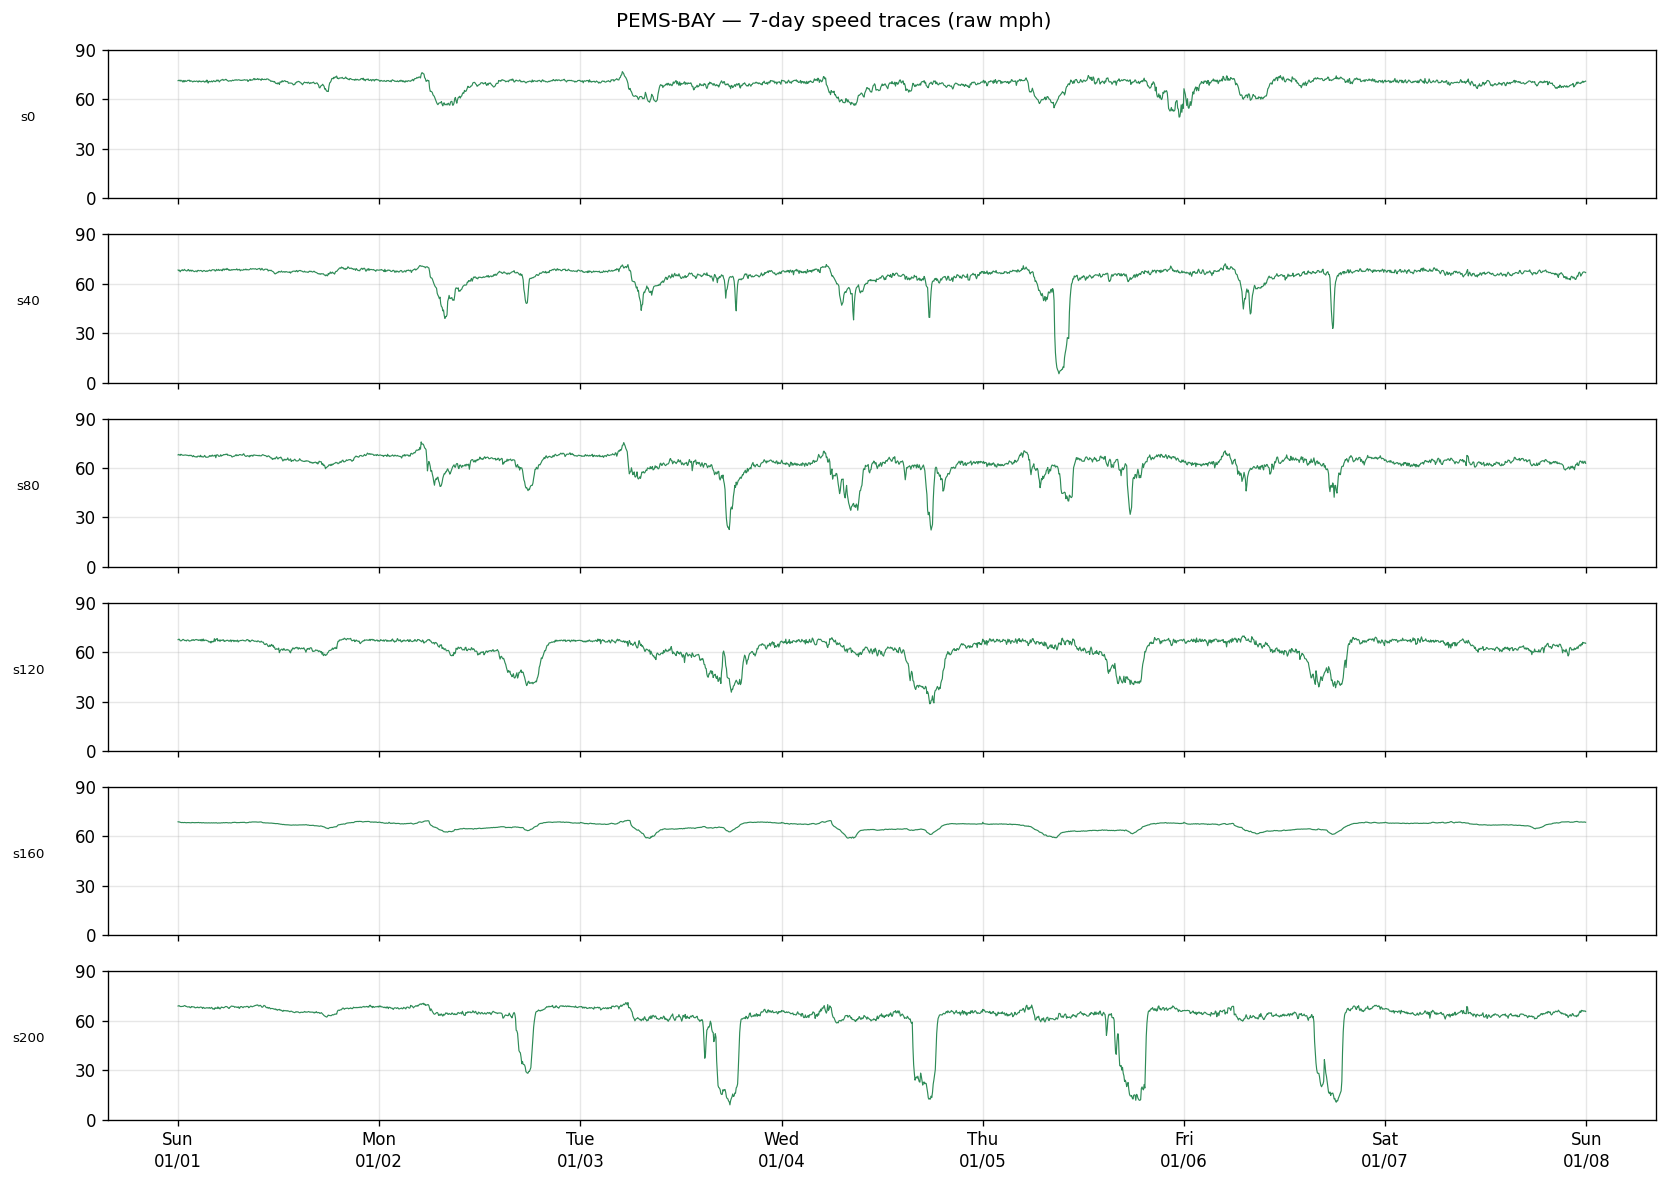

Saved fig_weekly_cycles_pemsbay.png


In [10]:
SENSORS_BAY = [0, 40, 80, 120, 160, 200]
N_DAYS_BAY  = 7
N_STEPS_BAY = N_DAYS_BAY * 288

fig, axes = plt.subplots(len(SENSORS_BAY), 1, figsize=(14, 10), sharex=True)
fig.suptitle('PEMS-BAY — 7-day speed traces (raw mph)', fontsize=12)

times_bay = df_bay.index[:N_STEPS_BAY]
for ax, s in zip(axes, SENSORS_BAY):
    speed = df_bay.values[:N_STEPS_BAY, s].copy().astype(float)
    speed[speed == 0.0] = np.nan
    ax.plot(times_bay, speed, linewidth=0.7, color='seagreen')
    ax.set_ylabel(f's{s}', fontsize=8, rotation=0, labelpad=28)
    ax.set_ylim(0, 90)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(30))
    ax.grid(alpha=0.3)

axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%a\n%m/%d'))
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_weekly_cycles_pemsbay.png', bbox_inches='tight')
plt.show()
print('Saved fig_weekly_cycles_pemsbay.png')

### PEMS-BAY — Figure: Missingness heatmap

PEMS-BAY sensors with >10% missing: 0
Max missing rate: 0.0%  (sensor 237)


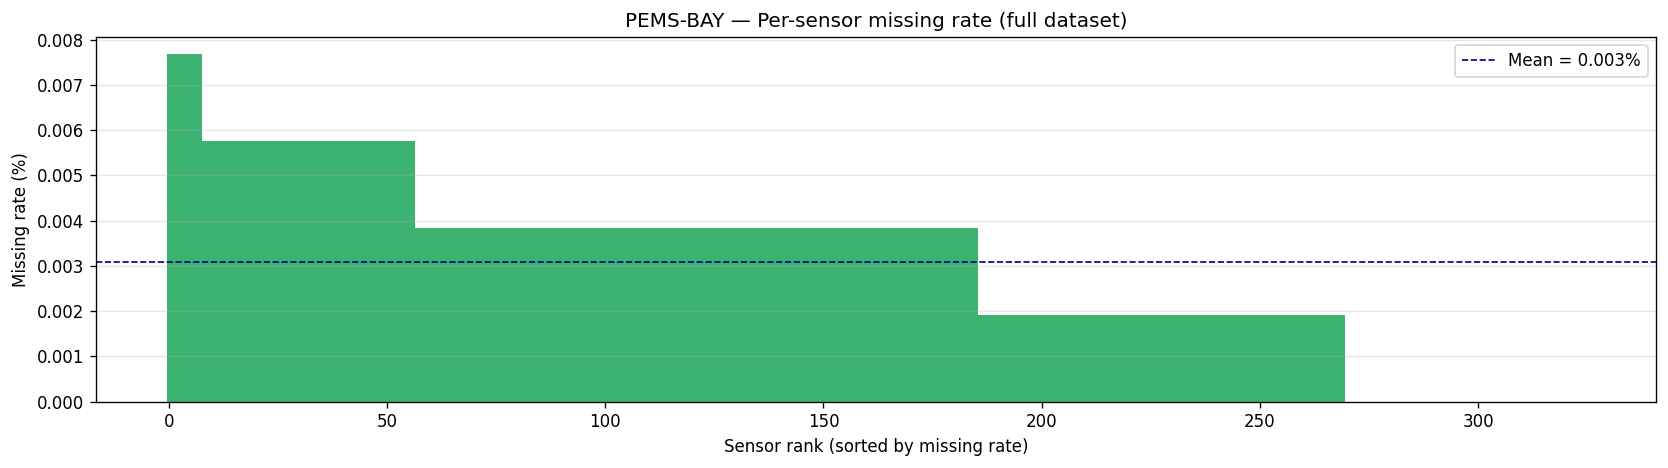

Saved fig_missingness_heatmap_pemsbay.png


In [11]:
order_bay = np.argsort(missing_rate_bay)[::-1]
print(f'PEMS-BAY sensors with >10% missing: {(missing_rate_bay > 0.1).sum()}')
print(f'Max missing rate: {missing_rate_bay.max()*100:.1f}%  (sensor {missing_rate_bay.argmax()})')

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(np.arange(N_bay), missing_rate_bay[order_bay] * 100,
       width=1.0, color='mediumseagreen', edgecolor='none')
ax.set_xlabel('Sensor rank (sorted by missing rate)')
ax.set_ylabel('Missing rate (%)')
ax.set_title('PEMS-BAY — Per-sensor missing rate (full dataset)')
ax.axhline(missing_rate_bay.mean()*100, color='navy', linestyle='--', linewidth=1,
           label=f'Mean = {missing_rate_bay.mean()*100:.3f}%')
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_missingness_heatmap_pemsbay.png', bbox_inches='tight')
plt.show()
print('Saved fig_missingness_heatmap_pemsbay.png')

### PEMS-BAY — Figure: ACF raw vs de-meaned speed

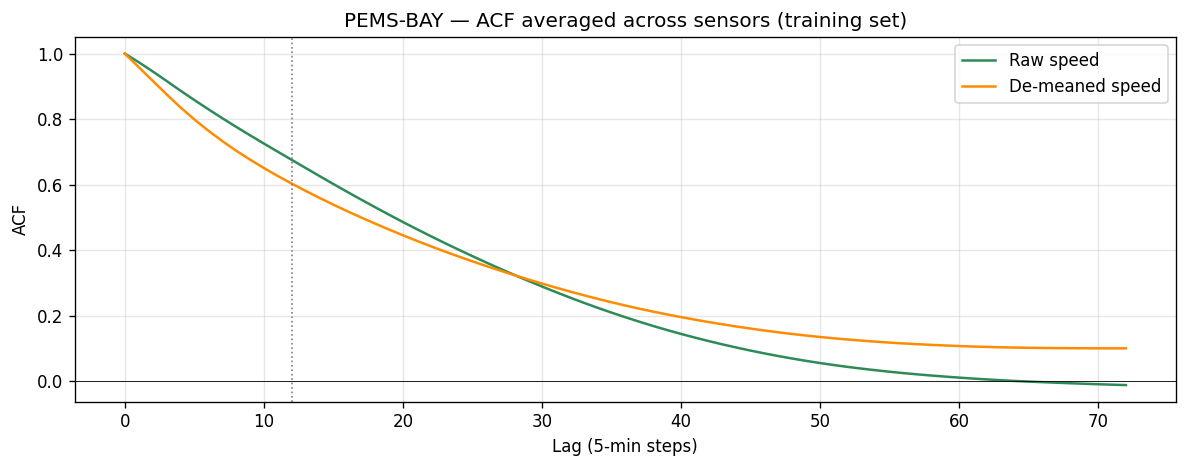

Saved fig_acf_raw_vs_demeaned_pemsbay.png


In [12]:
from statsmodels.tsa.stattools import acf as _acf

MAX_LAG_BAY = 72
N_TRAIN_T_BAY_ACF = train_bay['x'].shape[0] + 23   # = 36481

speed_train_bay = df_bay.values[:N_TRAIN_T_BAY_ACF].astype(float)   # (36481, 325)

tod_idx_bay = (df_bay.index[:N_TRAIN_T_BAY_ACF].values
               - df_bay.index[:N_TRAIN_T_BAY_ACF].values.astype('datetime64[D]')
              ) / np.timedelta64(5, 'm')
tod_idx_bay = tod_idx_bay.astype(int)

tod_means_bay = np.zeros((288, N_bay))
for slot in range(288):
    mask_slot = tod_idx_bay == slot
    if mask_slot.sum() > 0:
        vals = speed_train_bay[mask_slot]
        valid_vals = np.where(vals == 0, np.nan, vals)
        tod_means_bay[slot] = np.nanmean(valid_vals, axis=0)

speed_demeaned_bay = speed_train_bay.copy()
for t in range(N_TRAIN_T_BAY_ACF):
    speed_demeaned_bay[t] -= tod_means_bay[tod_idx_bay[t]]

good_sensors_bay = np.where(missing_rate_bay < 0.5)[0]
acf_raw_bay = np.zeros((len(good_sensors_bay), MAX_LAG_BAY + 1))
acf_dem_bay = np.zeros((len(good_sensors_bay), MAX_LAG_BAY + 1))

for i, s in enumerate(good_sensors_bay):
    raw_s = speed_train_bay[:, s].copy()
    raw_s[raw_s == 0] = np.nan
    valid = ~np.isnan(raw_s)
    if valid.sum() > MAX_LAG_BAY * 2:
        acf_raw_bay[i] = _acf(raw_s[valid], nlags=MAX_LAG_BAY, fft=True)
        dem_s = speed_demeaned_bay[:, s][valid]
        acf_dem_bay[i] = _acf(dem_s, nlags=MAX_LAG_BAY, fft=True)

mean_acf_raw_bay = acf_raw_bay.mean(axis=0)
mean_acf_dem_bay = acf_dem_bay.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
lags = np.arange(MAX_LAG_BAY + 1)
ax.plot(lags, mean_acf_raw_bay, label='Raw speed',       color='seagreen',    linewidth=1.5)
ax.plot(lags, mean_acf_dem_bay, label='De-meaned speed', color='darkorange',  linewidth=1.5)
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Lag (5-min steps)')
ax.set_ylabel('ACF')
ax.set_title('PEMS-BAY — ACF averaged across sensors (training set)')
ax.legend()
ax.axvline(12, color='gray', linestyle=':', linewidth=1, label='h=12')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_acf_raw_vs_demeaned_pemsbay.png', bbox_inches='tight')
plt.show()
print('Saved fig_acf_raw_vs_demeaned_pemsbay.png')

In [13]:
# PEMS-BAY: Laplacian eigendecomposition (cached to data/processed/)
adj_bay = load_adjacency("pemsbay")
L_bay   = compute_normalized_laplacian(adj_bay)
eigs_bay, _ = laplacian_eigendecomposition(L_bay, "pemsbay")
print(f"PEMS-BAY Laplacian eigenvalue range: [{eigs_bay.min():.4f}, {eigs_bay.max():.4f}]")
assert eigs_bay.min() >= -1e-6, "Laplacian not PSD"
print("Saved → data/processed/pemsbay_laplacian_eigs.npz")

PEMS-BAY Laplacian eigenvalue range: [0.0000, 1.8083]
Saved → data/processed/pemsbay_laplacian_eigs.npz


/Users/serkan/Projects/research-tud/src/data/adjacency.py:40: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  _, _, adj_mx = pickle.load(f, encoding="latin1")
/Users/serkan/Projects/research-tud/src/data/adjacency.py:65: RuntimeWarning: divide by zero encountered in divide
  d_inv_sqrt = np.where(d > 0, 1.0 / np.sqrt(d), 0.0)


PEMS-BAY Mean Dirichlet energy: 0.048351


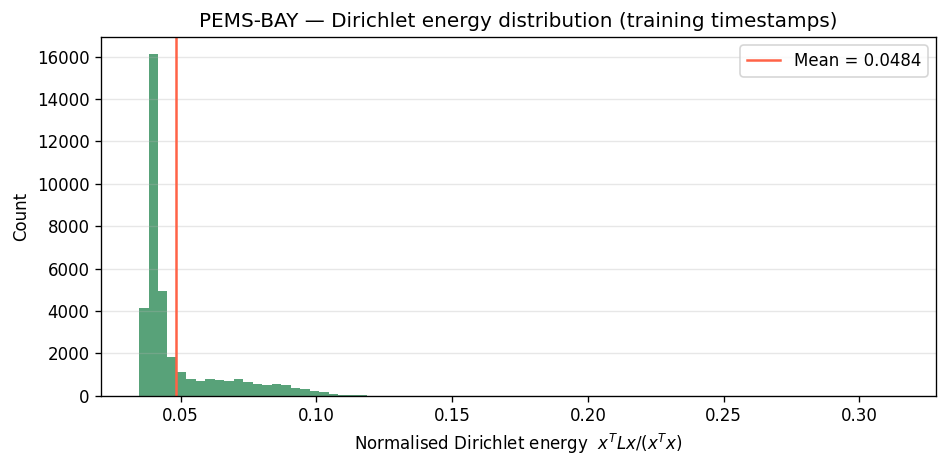

Saved fig_dirichlet_energy_pemsbay.png


In [14]:
# PEMS-BAY: Dirichlet energy distribution
N_TRAIN_T_BAY = train_bay['x'].shape[0] + 23   # recover T_train from window count
speed_t_bay = df_bay.values[:N_TRAIN_T_BAY].astype(np.float32)

L_bay32 = L_bay.astype(np.float32)
xL_bay  = speed_t_bay @ L_bay32
xLx_bay = (xL_bay * speed_t_bay).sum(axis=1)
xx_bay  = (speed_t_bay * speed_t_bay).sum(axis=1)
dirichlet_bay = xLx_bay / (xx_bay + 1e-8)
mean_dirichlet_bay = float(dirichlet_bay.mean())
print(f"PEMS-BAY Mean Dirichlet energy: {mean_dirichlet_bay:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dirichlet_bay, bins=80, color='seagreen', edgecolor='none', alpha=0.8)
ax.axvline(mean_dirichlet_bay, color='tomato', linewidth=1.5,
           label=f'Mean = {mean_dirichlet_bay:.4f}')
ax.set_xlabel('Normalised Dirichlet energy  $x^T L x / (x^T x)$')
ax.set_ylabel('Count')
ax.set_title('PEMS-BAY — Dirichlet energy distribution (training timestamps)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_dirichlet_energy_pemsbay.png', bbox_inches='tight')
plt.show()
print('Saved fig_dirichlet_energy_pemsbay.png')

In [15]:
# PEMS-BAY: regime labels for test split
x_test_bay  = test_bay["x"]          # (N_test, 12, 325, 2)  — raw speed in channel 0
x_mask_bay  = test_bay["x_mask"]     # (N_test, 12, 325, 1)

raw_x_speed_bay = x_test_bay[..., 0]
valid_bay = x_mask_bay[..., 0].astype(bool)
masked_speed_bay = np.where(valid_bay, raw_x_speed_bay, np.nan)
window_mean_bay = np.nanmean(masked_speed_bay.reshape(len(x_test_bay), -1), axis=1)

# Fill any all-missing windows with global mean
global_mean_bay = float(np.nanmean(window_mean_bay))
window_mean_bay = np.where(np.isnan(window_mean_bay), global_mean_bay, window_mean_bay)

t33_bay, t67_bay = np.percentile(window_mean_bay, [33.33, 66.67])
regime_bay = np.where(window_mean_bay >= t67_bay, "free_flow",
             np.where(window_mean_bay <= t33_bay, "congested", "transition"))

print(f"PEMS-BAY test windows: {len(regime_bay)}")
for r in ["free_flow", "transition", "congested"]:
    n = (regime_bay == r).sum()
    print(f"  {r:12s}: {n} ({n/len(regime_bay)*100:.1f}%)")
print(f"Speed thresholds: congested<{t33_bay:.1f} mph, free_flow>{t67_bay:.1f} mph")

out_path_bay = Path("data/processed/pemsbay_regimes_test.npz")
np.savez(out_path_bay, regime=regime_bay)
print(f"Saved regime labels → {out_path_bay}")

PEMS-BAY test windows: 10400
  free_flow   : 3467 (33.3%)
  transition  : 3466 (33.3%)
  congested   : 3467 (33.3%)
Speed thresholds: congested<61.9 mph, free_flow>66.3 mph
Saved regime labels → data/processed/pemsbay_regimes_test.npz


---
## Cross-dataset comparison

Side-by-side figures comparing METR-LA and PEMS-BAY on temporal structure,
spatial smoothness, and traffic regime distribution.

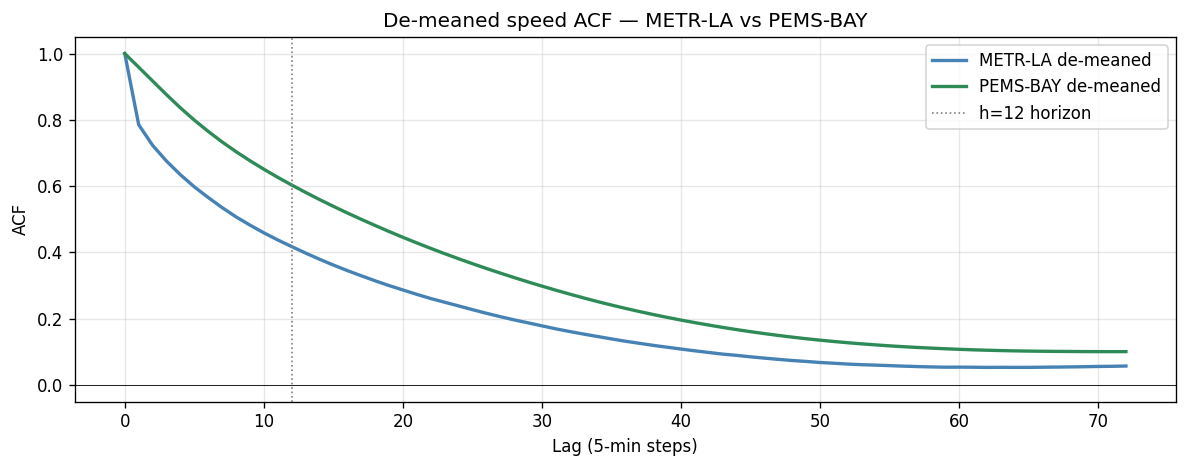

Saved fig_acf_comparison.png


In [16]:
# --- Comparison 1: ACF overlay (de-meaned only) ---
fig, ax = plt.subplots(figsize=(10, 4))
lags = np.arange(MAX_LAG + 1)
ax.plot(lags, mean_acf_dem,     label='METR-LA de-meaned',  color='steelblue', linewidth=2)
ax.plot(lags, mean_acf_dem_bay, label='PEMS-BAY de-meaned', color='seagreen',  linewidth=2)
ax.axhline(0, color='k', linewidth=0.5)
ax.axvline(12, color='gray', linestyle=':', linewidth=1, label='h=12 horizon')
ax.set_xlabel('Lag (5-min steps)')
ax.set_ylabel('ACF')
ax.set_title('De-meaned speed ACF — METR-LA vs PEMS-BAY')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_acf_comparison.png', bbox_inches='tight')
plt.show()
print('Saved fig_acf_comparison.png')

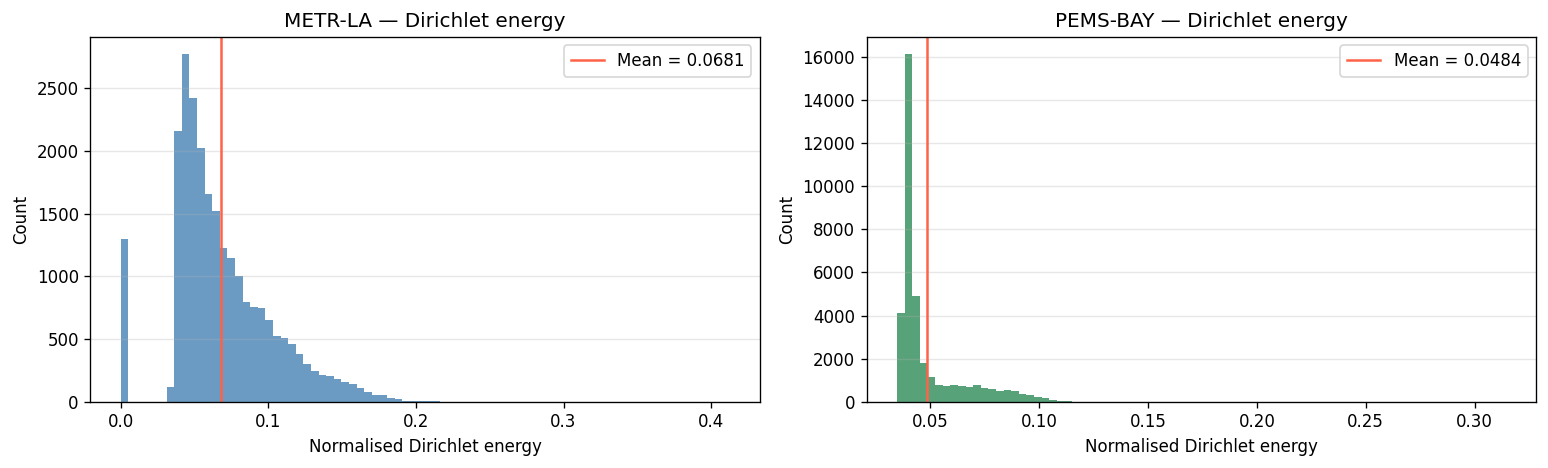

Dirichlet energy:  METR-LA mean=0.0681  PEMS-BAY mean=0.0484
Saved fig_dirichlet_comparison.png


In [17]:
# --- Comparison 2: Dirichlet energy side by side ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

for ax, de, label, color, mean_val in [
    (axes[0], dirichlet,     'METR-LA',  'steelblue', mean_dirichlet),
    (axes[1], dirichlet_bay, 'PEMS-BAY', 'seagreen',  mean_dirichlet_bay),
]:
    ax.hist(de, bins=80, color=color, edgecolor='none', alpha=0.8)
    ax.axvline(mean_val, color='tomato', linewidth=1.5, label=f'Mean = {mean_val:.4f}')
    ax.set_xlabel('Normalised Dirichlet energy')
    ax.set_ylabel('Count')
    ax.set_title(f'{label} — Dirichlet energy')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_dirichlet_comparison.png', bbox_inches='tight')
plt.show()
print(f'Dirichlet energy:  METR-LA mean={mean_dirichlet:.4f}  PEMS-BAY mean={mean_dirichlet_bay:.4f}')
print('Saved fig_dirichlet_comparison.png')

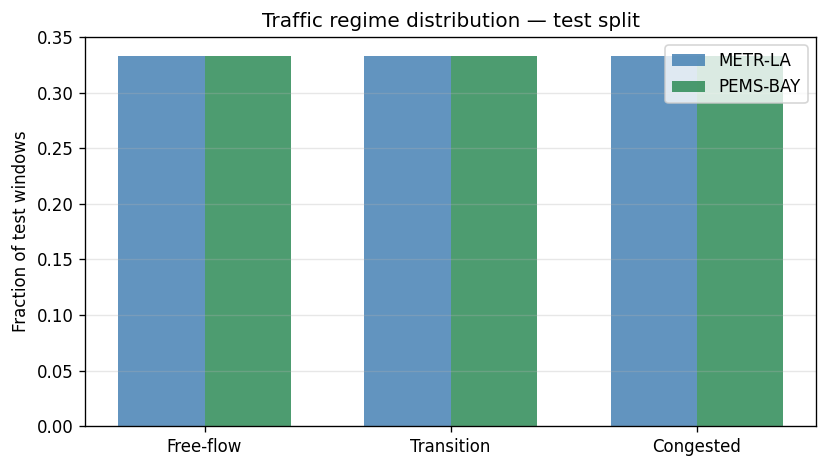

Regime fractions (test split):
  free_flow     METR-LA=33.3%  PEMS-BAY=33.3%
  transition    METR-LA=33.3%  PEMS-BAY=33.3%
  congested     METR-LA=33.3%  PEMS-BAY=33.3%
Saved fig_regime_comparison.png


In [18]:
# --- Comparison 3: Regime distribution ---
regimes_la  = np.load("data/processed/metrla_regimes_test.npz")["regime"]
regimes_bay = np.load("data/processed/pemsbay_regimes_test.npz")["regime"]

labels = ["free_flow", "transition", "congested"]
counts_la  = [float((regimes_la  == r).mean()) for r in labels]
counts_bay = [float((regimes_bay == r).mean()) for r in labels]

x = np.arange(len(labels))
w = 0.35
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, counts_la,  w, label='METR-LA',  color='steelblue', alpha=0.85)
ax.bar(x + w/2, counts_bay, w, label='PEMS-BAY', color='seagreen',  alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(['Free-flow', 'Transition', 'Congested'])
ax.set_ylabel('Fraction of test windows')
ax.set_title('Traffic regime distribution — test split')
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_regime_comparison.png', bbox_inches='tight')
plt.show()

print('Regime fractions (test split):')
for r, la, bay in zip(labels, counts_la, counts_bay):
    print(f'  {r:12s}  METR-LA={la*100:.1f}%  PEMS-BAY={bay*100:.1f}%')
print('Saved fig_regime_comparison.png')

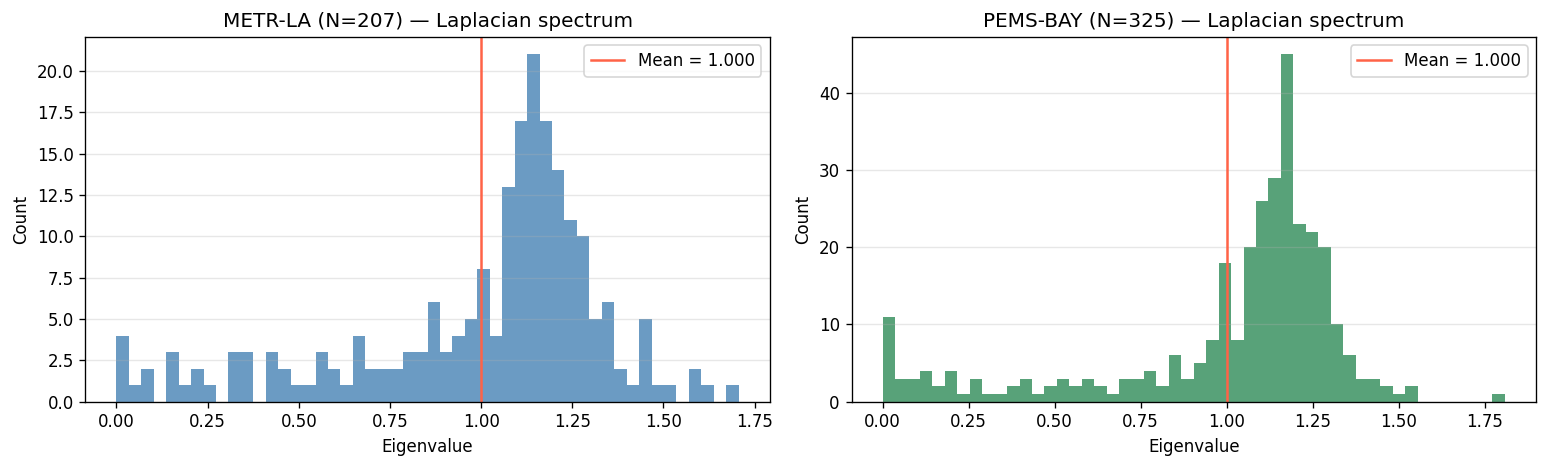

Laplacian spectra:
  METR-LA  : min=0.0000  max=1.7062  mean=1.0000
  PEMS-BAY : min=0.0000  max=1.8083  mean=1.0000
Saved fig_laplacian_spectrum_comparison.png


In [19]:
# --- Comparison 4: Laplacian eigenvalue spectrum ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, eigs, label, color in [
    (axes[0], eigenvalues, 'METR-LA (N=207)',  'steelblue'),
    (axes[1], eigs_bay,    'PEMS-BAY (N=325)', 'seagreen'),
]:
    ax.hist(eigs, bins=50, color=color, edgecolor='none', alpha=0.8)
    ax.axvline(eigs.mean(), color='tomato', linewidth=1.5, label=f'Mean = {eigs.mean():.3f}')
    ax.set_xlabel('Eigenvalue')
    ax.set_ylabel('Count')
    ax.set_title(f'{label} — Laplacian spectrum')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig_laplacian_spectrum_comparison.png', bbox_inches='tight')
plt.show()
print(f'Laplacian spectra:')
print(f'  METR-LA  : min={eigenvalues.min():.4f}  max={eigenvalues.max():.4f}  mean={eigenvalues.mean():.4f}')
print(f'  PEMS-BAY : min={eigs_bay.min():.4f}  max={eigs_bay.max():.4f}  mean={eigs_bay.mean():.4f}')
print('Saved fig_laplacian_spectrum_comparison.png')

## Summary

In [20]:
print('=== EDA Summary ===')
print()
print('--- METR-LA ---')
print(f'Dataset       : METR-LA, T={T}, N={N}')
print(f'Date range    : {df_raw.index[0]}  →  {df_raw.index[-1]}')
print(f'Missing rate  : {missing_rate.mean()*100:.3f}% mean, {missing_rate.max()*100:.1f}% max')
print(f'Speed range   : [{df_raw.values[df_raw.values>0].min():.1f}, {df_raw.values.max():.1f}] mph')
print(f'Scaler        : mean={MEAN:.4f}, std={STD:.4f}')
print(f'y_train mean  : {y_mean:.4f} mph  (raw, not normalised)')
print(f'Laplacian eig : [{eigenvalues.min():.4f}, {eigenvalues.max():.4f}]')
print(f'Dirichlet energy mean: {mean_dirichlet:.6f}')
print(f'Regime thresholds: congested<{t33:.1f}, free_flow>{t67:.1f} mph')
print()
print('--- PEMS-BAY ---')
print(f'Dataset       : PEMS-BAY, T={T_bay}, N={N_bay}')
print(f'Date range    : {df_bay.index[0]}  →  {df_bay.index[-1]}')
print(f'Missing rate  : {missing_rate_bay.mean()*100:.3f}% mean, {missing_rate_bay.max()*100:.1f}% max')
print(f'Scaler        : mean={MEAN_BAY:.4f}, std={STD_BAY:.4f}')
print(f'y_train mean  : {y_bay_mean:.4f} mph  (raw, not normalised)')
print(f'Laplacian eig : [{eigs_bay.min():.4f}, {eigs_bay.max():.4f}]')
print(f'Dirichlet energy mean: {mean_dirichlet_bay:.6f}')
print(f'Regime thresholds: congested<{t33_bay:.1f}, free_flow>{t67_bay:.1f} mph')
print()
print('Figures saved to results/figures/eda/')
print('Processed files: metrla_regimes_test.npz, pemsbay_regimes_test.npz,')
print('                 metrla_laplacian_eigs.npz, pemsbay_laplacian_eigs.npz')

=== EDA Summary ===

--- METR-LA ---
Dataset       : METR-LA, T=34272, N=207
Date range    : 2012-03-01 00:00:00  →  2012-06-27 23:55:00
Missing rate  : 8.109% mean, 20.1% max
Speed range   : [0.3, 70.0] mph
Scaler        : mean=54.4059, std=19.4943
y_train mean  : 54.4056 mph  (raw, not normalised)
Laplacian eig : [0.0000, 1.7062]
Dirichlet energy mean: 0.068068
Regime thresholds: congested<57.2, free_flow>61.0 mph

--- PEMS-BAY ---
Dataset       : PEMS-BAY, T=52116, N=325
Date range    : 2017-01-01 00:00:00  →  2017-06-30 23:55:00
Missing rate  : 0.003% mean, 0.0% max
Scaler        : mean=62.7369, std=9.4368
y_train mean  : 62.7341 mph  (raw, not normalised)
Laplacian eig : [0.0000, 1.8083]
Dirichlet energy mean: 0.048351
Regime thresholds: congested<61.9, free_flow>66.3 mph

Figures saved to results/figures/eda/
Processed files: metrla_regimes_test.npz, pemsbay_regimes_test.npz,
                 metrla_laplacian_eigs.npz, pemsbay_laplacian_eigs.npz
